Concepts and association rules.

In [1]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn
from query import *
from contexts import *
from myconcepts import *
from concepts import Definition, Context

In [43]:
proc_nameQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').values('cmd').as('name').select('pid','name').dedup()"
nameCtxt = makeContext(getQuery(proc_nameQ),'pid','name')
nameCtxt

{}

In [3]:
eventCtxt = makeContext(getQuery(proc_eventQ),'pid','type')
eventCtxt

{'709': {'EVENT_ACCEPT', 'EVENT_CLONE', 'EVENT_CREATE_OBJECT'},
 '3138': {'EVENT_MMAP',
  'EVENT_OPEN',
  'EVENT_OTHER',
  'EVENT_READ',
  'EVENT_WRITE'},
 '3244': {'EVENT_CLONE',
  'EVENT_CREATE_OBJECT',
  'EVENT_OPEN',
  'EVENT_OTHER',
  'EVENT_READ',
  'EVENT_WRITE'},
 '3366': {'EVENT_CONNECT',
  'EVENT_MMAP',
  'EVENT_OPEN',
  'EVENT_OTHER',
  'EVENT_SENDTO'},
 '3373': {'EVENT_CLONE',
  'EVENT_CREATE_OBJECT',
  'EVENT_OPEN',
  'EVENT_OTHER',
  'EVENT_READ'},
 '1804': {'EVENT_MMAP', 'EVENT_OPEN', 'EVENT_READ'},
 '1418': {'EVENT_CLONE', 'EVENT_OPEN', 'EVENT_READ'},
 '3474': {'EVENT_CLONE'},
 '761': {'EVENT_ACCEPT'},
 '679': {'EVENT_OPEN', 'EVENT_READ'},
 '772': {'EVENT_ACCEPT',
  'EVENT_MMAP',
  'EVENT_OPEN',
  'EVENT_OTHER',
  'EVENT_WRITE'},
 '1883': {'EVENT_CLONE'},
 '1023': {'EVENT_CLONE',
  'EVENT_CREATE_OBJECT',
  'EVENT_OPEN',
  'EVENT_READ',
  'EVENT_WRITE'},
 '2826': {'EVENT_CLONE'},
 '3475': {'EVENT_CLONE',
  'EVENT_CREATE_OBJECT',
  'EVENT_EXECUTE',
  'EVENT_MMAP',
  'EVEN

In [9]:
len(eventCtxt)

1965

In [4]:
def mkCtxt(context): 
    d = Definition()
    for label in context.keys():
        d.add_object(label, context[label])
    c = Context(*d)
    return c

In [5]:
dot1 = mkCtxt(eventCtxt).lattice.graphviz()
dot1

KeyboardInterrupt: 

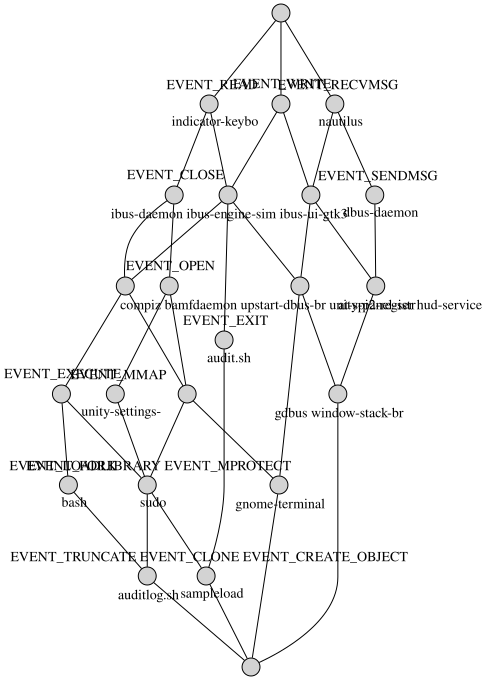

In [6]:
name_eventQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('name').as('name').select('x').in().hasLabel('Event').as('y').values('eventType').as('type').select('name','type').dedup()"
nameEventCtxt = makeContext(getQuery(name_eventQ),'name','type')
dot4 = mkCtxt(nameEventCtxt).lattice.graphviz()
#dot4.render('test-output/eventName', view=True)
dot4

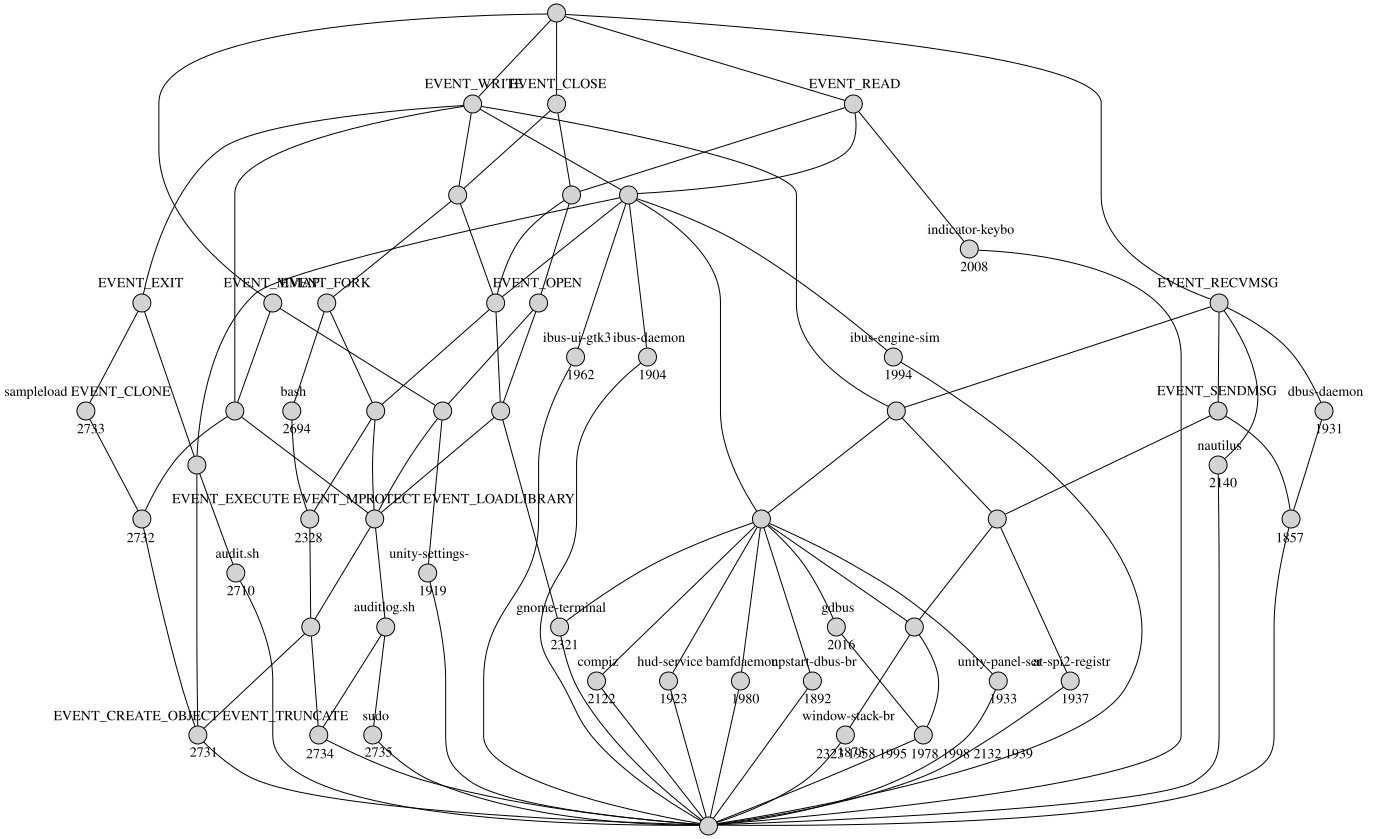

In [7]:
def combineContexts(ctx1,ctx2):
    ctx = ctx1.copy()
    for k in ctx2.keys():
        if k in ctx1.keys(): 
            ctx[k] = ctx[k] | ctx2[k]
        else:
            ctx[k] = ctx2[k]
    return ctx
context = combineContexts(eventCtxt,nameCtxt)
#dot2 = mkCtxt(context).lattice.graphviz()
#dot2.render('test-output/context', view=True)

#dot2

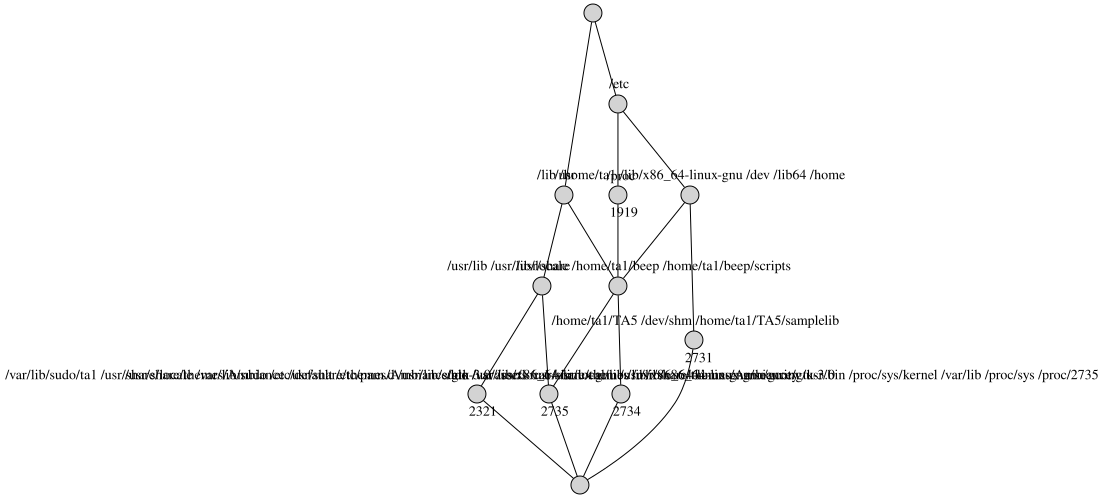

In [9]:
fileCtxt = makeContext(getQuery(proc_fileQ),'pid','file')
prefFileCtxt = {k : allprefixes(fileCtxt[k]) for k in fileCtxt.keys()}
ctx = combineContexts(prefFileCtxt,context)
mkCtxt(prefFileCtxt).lattice.graphviz()


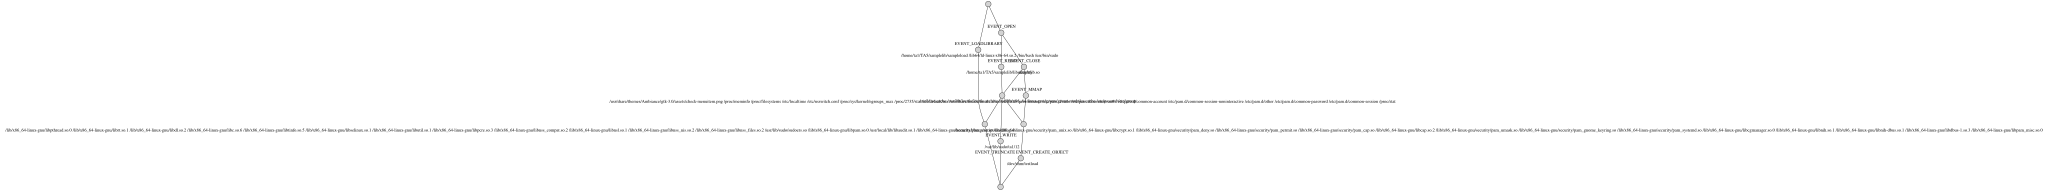

In [10]:
file_eventQ = "g.V().hasLabel('FileObject').as('z').values('path').as('file').select('z').in().hasLabel('Event').as('y').values('eventType').as('type').select('file','type')"
fileEventCtxt = makeContext(getQuery(file_eventQ),'file','type')
mkCtxt(fileEventCtxt).lattice.graphviz()


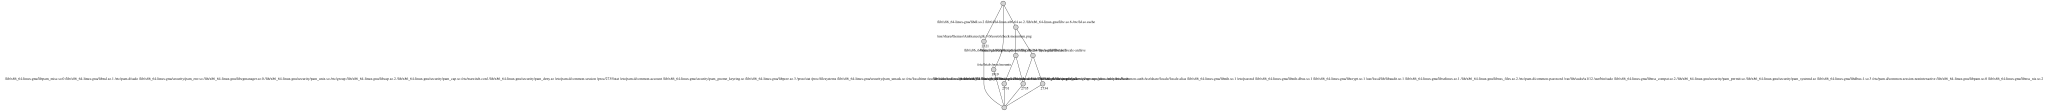

In [15]:
procFileCtxt = makeContext(getQuery(proc_fileQ),'pid','file')
dot = mkCtxt(procFileCtxt).lattice.graphviz()
dot.render('test-output/procFile', view=True)
dot

In [23]:
proc_writes_fileQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').in().hasLabel('Event').as('y').has('eventType','EVENT_WRITE').select('y').out().hasLabel('FileObject').as('z').values('path').as('file').select('pid','file').dedup()"
getQuery(proc_writes_fileQ)
#procWritesFileCtxt = makeContext(getQuery(proc_writes_fileQ),'pid','file')
#dot = mkCtxt(procFileCtxt).lattice.graphviz()
#dot.render('test-output/procFile', view=True)
#dot
#procWritesFileCtxt

[{'file': '/var/lib/sudo/ta1/12', 'pid': '2735'}]

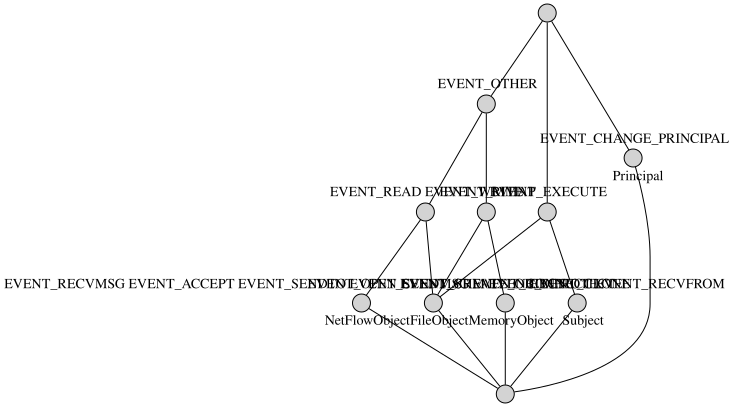

In [14]:
event_type_objectQ = "g.V().hasLabel('Event').as('y').values('eventType').as('type').select('y').out('predicateObject','predicateObject2').label().as('object').select('type','object').dedup()"
getQuery(event_type_objectQ)
eventObjectCtxt = makeContext(getQuery(event_type_objectQ),'object','type')
dot = mkCtxt(eventObjectCtxt).lattice.graphviz()
#dot.render('test-output/eventObject', view=True)
dot

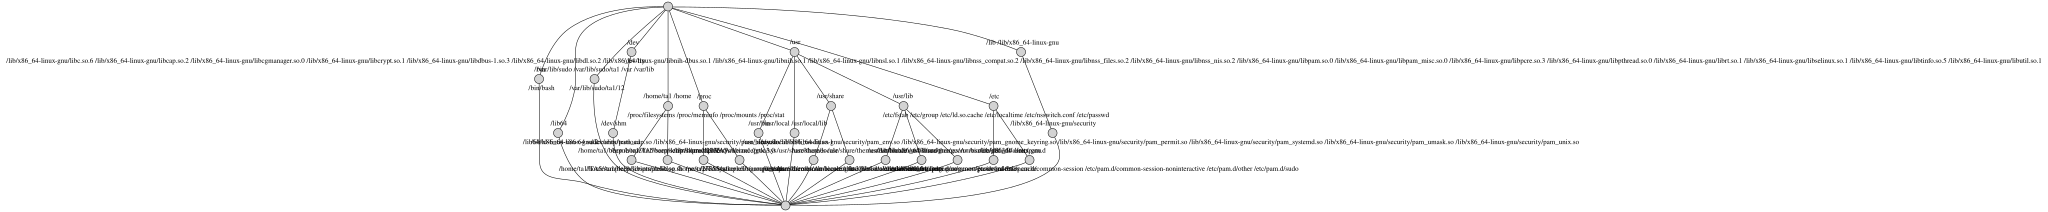

In [11]:
files = getQuery("g.V().hasLabel('FileObject').values('path').dedup().order()")
counter = 0
allFileCtxt = {}
for k in files:
    allFileCtxt[k] = prefixes(k)
mkCtxt(allFileCtxt).lattice.graphviz()



In [12]:
from datetime import datetime
def mkDate(t): 
    return datetime.fromtimestamp(int(t)/1000000000)
{mkDate(t) for t in getQuery(timestampQ)}

NameError: name 'timestampQ' is not defined

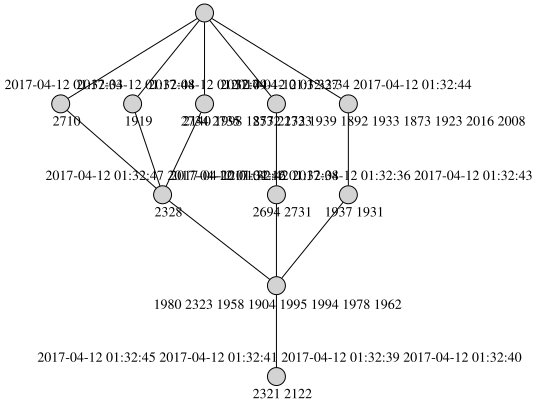

In [13]:
proc_eventTimeQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').in().hasLabel('Event').as('y').values('timestampNanos').as('time').select('pid','time').dedup()"
def secondsApprox(dt):
    return datetime(dt.year,dt.month,dt.day,dt.hour,dt.minute,dt.second)
procTime = [{'pid':etq['pid'], 'time':str(secondsApprox(mkDate(etq['time'])))} for etq in getQuery(proc_eventTimeQ)]
procTimeCtxt = makeContext(procTime,'pid','time')
mkCtxt(procTimeCtxt).lattice.graphviz()


In [8]:
concepts = findAllConceptsWithMinSupp(eventCtxt,0.05*len(eventCtxt))
concepts

{frozenset(),
 frozenset({'EVENT_CONNECT', 'EVENT_OPEN'}),
 frozenset({'EVENT_CLONE', 'EVENT_OTHER', 'EVENT_READ'}),
 frozenset({'EVENT_OPEN'}),
 frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}),
 frozenset({'EVENT_MMAP', 'EVENT_OPEN'}),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_OPEN', 'EVENT_READ'}),
 frozenset({'EVENT_CONNECT'}),
 frozenset({'EVENT_CONNECT', 'EVENT_OPEN', 'EVENT_READ'}),
 frozenset({'EVENT_CONNECT', 'EVENT_RECVFROM'}),
 frozenset({'EVENT_CONNECT', 'EVENT_RECVFROM', 'EVENT_SENDTO'}),
 frozenset({'EVENT_CONNECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_RECVFROM',
            'EVENT_SENDTO'}),
 frozenset({'EVENT_CONNECT',
            'EVENT_OPEN',
            'EVENT_OTHER',
            'EVENT_READ',
            'EVENT_RECVFROM',
            'EVENT_SENDTO'}),
 frozenset({'EVENT_CLONE', 'EVENT_OPEN', 'EVENT_READ'}),
 frozenset({'EVENT_CLONE', 'EVENT_CONNECT'}),
 frozenset({'EVENT_CLONE', 'EVENT_CONNECT', 'EVENT_OPEN', 'EVENT_REA

In [15]:
# naive
def successor(concepts,c1,c2):
    return c1 < c2 and {c for c in concepts if c1 < c and c < c2} == set()
def edges(concepts):
    return {(c1,c2) for c1 in concepts for c2 in concepts if successor(concepts,c1,c2)}
edges(concepts)

{(frozenset(), frozenset({'EVENT_CLONE'})),
 (frozenset(), frozenset({'EVENT_CONNECT'})),
 (frozenset(), frozenset({'EVENT_OPEN'})),
 (frozenset(), frozenset({'EVENT_READ'})),
 (frozenset(), frozenset({'EVENT_MPROTECT'})),
 (frozenset(), frozenset({'EVENT_CREATE_OBJECT'})),
 (frozenset(), frozenset({'EVENT_OTHER'})),
 (frozenset({'EVENT_OPEN', 'EVENT_READ'}),
  frozenset({'EVENT_OPEN', 'EVENT_OTHER', 'EVENT_READ'})),
 (frozenset({'EVENT_CLONE', 'EVENT_READ'}),
  frozenset({'EVENT_CLONE', 'EVENT_OTHER', 'EVENT_READ'})),
 (frozenset({'EVENT_CONNECT', 'EVENT_SENDTO'}),
  frozenset({'EVENT_CONNECT', 'EVENT_OPEN', 'EVENT_SENDTO'})),
 (frozenset({'EVENT_READ'}), frozenset({'EVENT_OPEN', 'EVENT_READ'})),
 (frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}),
  frozenset({'EVENT_EXECUTE',
             'EVENT_MMAP',
             'EVENT_MPROTECT',
             'EVENT_OPEN',
             'EVENT_READ'})),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN', 'EVENT_READ'}),
  frozenset({'EVENT_MMAP', 'EVE

In [17]:
getSupports(eventCtxt,concepts)

{frozenset(): 1965,
 frozenset({'EVENT_CONNECT', 'EVENT_OPEN'}): 317,
 frozenset({'EVENT_CLONE', 'EVENT_OTHER', 'EVENT_READ'}): 235,
 frozenset({'EVENT_OPEN'}): 1584,
 frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}): 1249,
 frozenset({'EVENT_MMAP', 'EVENT_OPEN'}): 1293,
 frozenset({'EVENT_READ'}): 1588,
 frozenset({'EVENT_OPEN', 'EVENT_READ'}): 1548,
 frozenset({'EVENT_CONNECT'}): 321,
 frozenset({'EVENT_CONNECT', 'EVENT_OPEN', 'EVENT_READ'}): 315,
 frozenset({'EVENT_CONNECT', 'EVENT_RECVFROM'}): 266,
 frozenset({'EVENT_CONNECT', 'EVENT_RECVFROM', 'EVENT_SENDTO'}): 252,
 frozenset({'EVENT_CONNECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_RECVFROM',
            'EVENT_SENDTO'}): 247,
 frozenset({'EVENT_CONNECT',
            'EVENT_OPEN',
            'EVENT_OTHER',
            'EVENT_READ',
            'EVENT_RECVFROM',
            'EVENT_SENDTO'}): 237,
 frozenset({'EVENT_CLONE', 'EVENT_OPEN', 'EVENT_READ'}): 287,
 frozenset({'EVENT_CLONE', 'EVENT

In [19]:
def getScaledSupports(context,concepts):
    supps = getSupports(context,concepts)
    n = len(context)
    return {k : supps[k]/n for k in supps.keys()}
getScaledSupports(eventCtxt,concepts)

{frozenset(): 1.0,
 frozenset({'EVENT_CONNECT', 'EVENT_OPEN'}): 0.16132315521628499,
 frozenset({'EVENT_CLONE', 'EVENT_OTHER', 'EVENT_READ'}): 0.11959287531806616,
 frozenset({'EVENT_OPEN'}): 0.8061068702290076,
 frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}): 0.6356234096692112,
 frozenset({'EVENT_MMAP', 'EVENT_OPEN'}): 0.6580152671755726,
 frozenset({'EVENT_READ'}): 0.8081424936386769,
 frozenset({'EVENT_OPEN', 'EVENT_READ'}): 0.7877862595419848,
 frozenset({'EVENT_CONNECT'}): 0.1633587786259542,
 frozenset({'EVENT_CONNECT', 'EVENT_OPEN', 'EVENT_READ'}): 0.16030534351145037,
 frozenset({'EVENT_CONNECT', 'EVENT_RECVFROM'}): 0.13536895674300253,
 frozenset({'EVENT_CONNECT',
            'EVENT_RECVFROM',
            'EVENT_SENDTO'}): 0.1282442748091603,
 frozenset({'EVENT_CONNECT',
            'EVENT_OPEN',
            'EVENT_READ',
            'EVENT_RECVFROM',
            'EVENT_SENDTO'}): 0.1256997455470738,
 frozenset({'EVENT_CONNECT',
            'EVENT_OPEN',
           

In [38]:
def getConfidence(context,concepts,minconf):
    supports = getSupports(context,concepts)
    edg = edges(concepts)
    return {(e[0],e[1]-e[0]): supports[e[1]]/supports[e[0]] for e in edg if supports[e[0]] > 0 and supports[e[1]]/supports[e[0]] > minconf}
rules = getConfidence(eventCtxt,concepts,0.95)

In [39]:
def violations(s,rules):
    ent = 0
    for e in rules.keys():
        if e[0] <= s and not(e[1] <= s):
            ent = ent - numpy.log2(1-rules[e])
    return ent
violations({'EVENT_MMAP','EVENT_READ'},rules)

5.3110671022555946

In [40]:
def allViolations(context,rules):
    return {k:violations(context[k],rules) for k in context.keys()}
vios = allViolations(eventCtxt,rules)
def snd(x): return x[1]
sorted(vios.items(),key=snd,reverse=True)

[('2765', 76.371105070483807),
 ('3366', 70.632455014411335),
 ('3802', 60.807880972982076),
 ('2693', 52.195909777634348),
 ('5104', 45.625316894434455),
 ('3521', 45.625316894434455),
 ('3903', 45.625316894434455),
 ('3696', 38.036742666895137),
 ('5105', 37.917957762353581),
 ('3522', 37.917957762353581),
 ('3904', 37.917957762353581),
 ('1731', 32.562249993257772),
 ('19493', 32.562249993257772),
 ('3691', 30.951897743285386),
 ('3797', 30.951897743285386),
 ('2688', 30.951897743285386),
 ('3847', 30.951897743285386),
 ('1818', 28.736390106566919),
 ('5372', 27.453922610163666),
 ('5711', 27.453922610163666),
 ('5712', 27.453922610163666),
 ('5019', 27.453922610163666),
 ('772', 24.148236309856273),
 ('2772', 24.148236309856273),
 ('1416', 22.975763270453747),
 ('3679', 22.975763270453747),
 ('3688', 22.975763270453747),
 ('3735', 22.975763270453747),
 ('3795', 22.975763270453747),
 ('1348', 22.975763270453747),
 ('3556', 12.099566981697338),
 ('3910', 12.099566981697338),
 ('3875'

TODO: Find 100% confidence rules, and infrequent combinations, as follows.  Consider all pairs of concepts X, Y.  Compute Z = (X U Y)'', the closure of the union of X and Y.  If Z - X U Y is nonempty and has large support, generate a 100% confidence rule X U Y -> Z.  (In principle could do this for all subsets of concepts but could be expensive.)  

To find infrequent combinations, look for X and Y such that Z = (X U Y)'' has small/no support.  Then X # Y is an infrequent combination rule (i.e. X U Y -> false)

In [41]:
def exactRules(context,concepts): 
    rules = set()
    for x in concepts:
        for y in concepts:
            xy = x | y
            z = getConcept(context,xy)
            diff = z - xy
            if z in concepts and diff != set():
                rules = rules | {(xy,diff)}
    return rules
exactRules(eventCtxt,concepts)

{(frozenset({'EVENT_CLONE', 'EVENT_CONNECT', 'EVENT_READ', 'EVENT_RECVFROM'}),
  frozenset({'EVENT_OPEN', 'EVENT_OTHER', 'EVENT_SENDTO'})),
 (frozenset({'EVENT_CLONE', 'EVENT_CONNECT', 'EVENT_OTHER'}),
  frozenset({'EVENT_OPEN', 'EVENT_READ'})),
 (frozenset({'EVENT_CLONE', 'EVENT_CONNECT', 'EVENT_RECVFROM'}),
  frozenset({'EVENT_SENDTO'})),
 (frozenset({'EVENT_CLONE',
             'EVENT_CONNECT',
             'EVENT_OPEN',
             'EVENT_OTHER',
             'EVENT_SENDTO'}),
  frozenset({'EVENT_READ'})),
 (frozenset({'EVENT_CONNECT', 'EVENT_READ'}), frozenset({'EVENT_OPEN'})),
 (frozenset({'EVENT_CONNECT', 'EVENT_READ', 'EVENT_RECVFROM'}),
  frozenset({'EVENT_OPEN'})),
 (frozenset({'EVENT_CLONE', 'EVENT_CONNECT', 'EVENT_READ', 'EVENT_SENDTO'}),
  frozenset({'EVENT_OPEN', 'EVENT_OTHER'})),
 (frozenset({'EVENT_CLONE',
             'EVENT_CONNECT',
             'EVENT_OTHER',
             'EVENT_READ',
             'EVENT_SENDTO'}),
  frozenset({'EVENT_OPEN'})),
 (frozenset({'EVENT

In [27]:
def disjointRuleImplied(r1,r2):
    (x1,y1) = r1
    (x2,y2) = r2
    return (x1 <= x2 and y1 <= y2) or (x1 <= y2 and y1 <= x2)
def disjointRuleRedundant(rules,r):
    for rule in rules:
        if disjointRuleImplied(rule,r):
            return True
    return False
disjointRuleImplied(({'a'},{'d'}),({'a','b'},{'c','d'}))


True

In [29]:
def updateRules(rules,r):
    return {rule for rule in rules if not disjointRuleImplied(r,rule)} | {r}
def disjointRules(context,concepts): 
    rules = set()
    for x in concepts:
        for y in concepts:
            if not(disjointRuleRedundant(rules,(x,y))):
                z = getConcept(context,x|y)
                if not(z in concepts):
                    rules = updateRules(rules,(x,y))
    return rules


drules = disjointRules(eventCtxt,concepts)
drules

{(frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}),
  frozenset({'EVENT_CREATE_OBJECT'})),
 (frozenset({'EVENT_CONNECT'}), frozenset({'EVENT_CREATE_OBJECT'})),
 (frozenset({'EVENT_MPROTECT'}), frozenset({'EVENT_OTHER'})),
 (frozenset({'EVENT_OTHER'}), frozenset({'EVENT_CREATE_OBJECT'})),
 (frozenset({'EVENT_MPROTECT'}), frozenset({'EVENT_CONNECT'})),
 (frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}),
  frozenset({'EVENT_OTHER'})),
 (frozenset({'EVENT_MPROTECT'}), frozenset({'EVENT_CLONE'})),
 (frozenset({'EVENT_MPROTECT'}), frozenset({'EVENT_CREATE_OBJECT'})),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN'}), frozenset({'EVENT_CLONE'})),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN'}), frozenset({'EVENT_CONNECT'})),
 (frozenset({'EVENT_CLONE'}), frozenset({'EVENT_CREATE_OBJECT'})),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN'}), frozenset({'EVENT_OTHER'})),
 (frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}),
  frozenset({'EVENT_CLONE'})),
 (frozenset({'EVENT_EXECUTE', 'EVENT_OPE

In [32]:
def druleViolations(s,drules):
    count = 0
    for rule in drules:
        if rule[0] <= s and rule[1] <= s:
            count = count + 1
    return count
def druleViolationsCtxt(context,drules):
    return {label:druleViolations(context[label],drules) for label in context.keys()}
dvios = druleViolationsCtxt(eventCtxt,drules)
sorted(dvios.items(),key=snd,reverse=True)

[('4320', 14),
 ('5144', 14),
 ('3556', 14),
 ('3910', 14),
 ('4553', 14),
 ('5455', 14),
 ('4785', 14),
 ('4024', 14),
 ('2686', 14),
 ('5104', 10),
 ('3521', 10),
 ('4427', 10),
 ('3903', 10),
 ('5250', 10),
 ('3671', 10),
 ('5372', 10),
 ('5373', 10),
 ('4659', 10),
 ('5583', 10),
 ('4891', 10),
 ('4153', 10),
 ('5711', 10),
 ('5719', 10),
 ('5019', 10),
 ('5020', 10),
 ('5105', 9),
 ('3522', 9),
 ('3904', 9),
 ('3475', 6),
 ('3873', 6),
 ('3885', 6),
 ('3547', 6),
 ('3548', 6),
 ('4549', 6),
 ('3688', 6),
 ('3726', 6),
 ('3746', 6),
 ('3752', 6),
 ('3773', 6),
 ('5560', 6),
 ('4130', 6),
 ('3785', 6),
 ('5712', 6),
 ('5714', 6),
 ('3795', 6),
 ('19605', 6),
 ('19606', 6),
 ('19607', 6),
 ('2699', 6),
 ('4312', 6),
 ('3844', 6),
 ('1419', 4),
 ('3714', 4),
 ('3818', 4),
 ('3477', 3),
 ('3481', 3),
 ('5086', 3),
 ('5088', 3),
 ('5089', 3),
 ('3482', 3),
 ('3483', 3),
 ('3484', 3),
 ('4315', 3),
 ('4316', 3),
 ('3858', 3),
 ('3861', 3),
 ('4323', 3),
 ('4324', 3),
 ('4325', 3),
 ('387

In [34]:
def importance(context,concepts):
    return {concept: len(concept) * getSupport(context,concept) for concept in concepts}
importances = importance(eventCtxt,concepts)
sorted(importances.items(),key=snd,reverse=True)

[(frozenset({'EVENT_EXECUTE',
             'EVENT_MMAP',
             'EVENT_MPROTECT',
             'EVENT_OPEN',
             'EVENT_READ'}),
  6240),
 (frozenset({'EVENT_MMAP', 'EVENT_MPROTECT', 'EVENT_OPEN', 'EVENT_READ'}),
  5016),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN', 'EVENT_READ'}), 3840),
 (frozenset({'EVENT_MPROTECT', 'EVENT_OPEN', 'EVENT_READ'}), 3777),
 (frozenset({'EVENT_EXECUTE', 'EVENT_OPEN', 'EVENT_READ'}), 3747),
 (frozenset({'EVENT_OPEN', 'EVENT_READ'}), 3096),
 (frozenset({'EVENT_MMAP', 'EVENT_OPEN'}), 2586),
 (frozenset({'EVENT_READ'}), 1588),
 (frozenset({'EVENT_OPEN'}), 1584),
 (frozenset({'EVENT_CLONE',
             'EVENT_CONNECT',
             'EVENT_OPEN',
             'EVENT_OTHER',
             'EVENT_READ',
             'EVENT_RECVFROM',
             'EVENT_SENDTO'}),
  1533),
 (frozenset({'EVENT_CONNECT',
             'EVENT_OPEN',
             'EVENT_OTHER',
             'EVENT_READ',
             'EVENT_RECVFROM',
             'EVENT_SENDTO'}),
  1422)

Remove all attribute subsets that are covered by a concept, and count how many attributes are left over.

In [42]:
def abnormality(concepts,attrs):
    matches = {concept for concept in concepts if concept <= attrs}
    for match in matches:
        attrs = attrs - match
    return len(attrs)
abnormals = {k: abnormality(concepts,eventCtxt[k]) for k in eventCtxt.keys()}
sorted(abnormals.items(),key=snd,reverse=True)

[('3688', 4),
 ('3795', 4),
 ('1103', 3),
 ('4320', 3),
 ('5144', 3),
 ('4553', 3),
 ('5455', 3),
 ('4785', 3),
 ('4024', 3),
 ('5712', 3),
 ('2686', 3),
 ('772', 2),
 ('735', 2),
 ('5372', 2),
 ('5711', 2),
 ('5019', 2),
 ('709', 1),
 ('3138', 1),
 ('3244', 1),
 ('761', 1),
 ('1023', 1),
 ('858', 1),
 ('5105', 1),
 ('4321', 1),
 ('3873', 1),
 ('3522', 1),
 ('5145', 1),
 ('4426', 1),
 ('1419', 1),
 ('1730', 1),
 ('3904', 1),
 ('3908', 1),
 ('5249', 1),
 ('3983', 1),
 ('3671', 1),
 ('3986', 1),
 ('3977', 1),
 ('3691', 1),
 ('3704', 1),
 ('3703', 1),
 ('1573', 1),
 ('3705', 1),
 ('3714', 1),
 ('3717', 1),
 ('5373', 1),
 ('4554', 1),
 ('3726', 1),
 ('3719', 1),
 ('4658', 1),
 ('3746', 1),
 ('3752', 1),
 ('5456', 1),
 ('3769', 1),
 ('3773', 1),
 ('3778', 1),
 ('5582', 1),
 ('3782', 1),
 ('4786', 1),
 ('4025', 1),
 ('4890', 1),
 ('3785', 1),
 ('4152', 1),
 ('853', 1),
 ('3797', 1),
 ('2566', 1),
 ('3810', 1),
 ('3809', 1),
 ('883', 1),
 ('2688', 1),
 ('2693', 1),
 ('3818', 1),
 ('3980', 1),

In [96]:
{concept for concept in concepts if getSupport(context,concept) > 12}

{frozenset(),
 frozenset({'EVENT_WRITE'}),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_READ', 'EVENT_WRITE'}),
 frozenset({'EVENT_RECVMSG'}),
 frozenset({'EVENT_RECVMSG', 'EVENT_WRITE'}),
 frozenset({'EVENT_READ', 'EVENT_RECVMSG', 'EVENT_WRITE'})}

In [97]:
testContext = {'a': {'y'}, 'f':{'x'},'b': {'z'},'c':{'x','y'},'d':{'y'},'e':{'y'}}
findAllConceptsWithMinSupp(testContext,2)

{frozenset(), frozenset({'x'}), frozenset({'y'})}

In [98]:
findAllConceptsWithMinSupp(context,20)

{frozenset(),
 frozenset({'EVENT_READ'}),
 frozenset({'EVENT_WRITE'}),
 frozenset({'EVENT_READ', 'EVENT_WRITE'})}

In [99]:
context = makeContext(getQuery(proc_child_nameQ),'parent','child')


In [100]:
getSupports(context,findAllConceptsWithMinSupp(context,0.1*len(context)))

{frozenset(): 6,
 frozenset({'auditlog.sh'}): 2,
 frozenset({'bash'}): 3,
 frozenset({'auditlog.sh', 'bash'}): 1,
 frozenset({'bash', 'sampleload'}): 1,
 frozenset({'gdbus', 'ibus-engine-sim', 'ibus-ui-gtk3'}): 1,
 frozenset({'auditlog.sh', 'sudo'}): 1,
 frozenset({'sampleload'}): 2}

In [ ]:
context = makeContext(getQuery(proc_fileQ),'pid','file')

In [ ]:
getSupports(context,findAllConceptsWithMinSupp(context,0.2*len(context)))

In [38]:
context2 = {k:allprefixes(context[k]) for k in context.keys()}

In [39]:
getSupports(context2,findAllConceptsWithMinSupp(context2,0.1*len(context2)))

{frozenset(): 5,
 frozenset({'/etc'}): 4,
 frozenset({'/usr', '/usr/share'}): 2,
 frozenset({'/dev',
            '/etc',
            '/home',
            '/home/ta1',
            '/lib',
            '/lib/x86_64-linux-gnu',
            '/lib64'}): 3,
 frozenset({'/dev',
            '/dev/shm',
            '/etc',
            '/home',
            '/home/ta1',
            '/home/ta1/TA5',
            '/home/ta1/TA5/samplelib',
            '/lib',
            '/lib/x86_64-linux-gnu',
            '/lib64'}): 1,
 frozenset({'/etc', '/proc'}): 3,
 frozenset({'/usr'}): 3,
 frozenset({'/dev',
            '/etc',
            '/etc/default',
            '/etc/pam.d',
            '/home',
            '/home/ta1',
            '/home/ta1/beep',
            '/home/ta1/beep/scripts',
            '/lib',
            '/lib/x86_64-linux-gnu',
            '/lib/x86_64-linux-gnu/security',
            '/lib64',
            '/proc',
            '/proc/2735',
            '/proc/sys',
            '/proc/sys/

In [40]:
bagofwords(" a b cde f ",' ')

{'a', 'b', 'cde', 'f'}

In [41]:
allbagofwords({'a b cde f', ' gh i jkl '}, ' ')

{'a', 'b', 'cde', 'f', 'gh', 'i', 'jkl'}

In [43]:
context3 = {k:allbagofwords(context[k],'/') for k in context.keys()}

In [45]:
getSupports(context3,findAllConceptsWithMinSupp(context3,0.1*len(context3)))

{frozenset(): 5,
 frozenset({'etc'}): 4,
 frozenset({'etc', 'proc'}): 3,
 frozenset({'etc', 'fstab', 'mounts', 'proc'}): 1,
 frozenset({'dev',
            'etc',
            'home',
            'ld-linux-x86-64.so.2',
            'ld.so.cache',
            'lib',
            'lib64',
            'libc.so.6',
            'libdl.so.2',
            'ta1',
            'x86_64-linux-gnu'}): 3,
 frozenset({'usr'}): 3,
 frozenset({'auditlog.sh',
            'beep',
            'bin',
            'dev',
            'etc',
            'home',
            'ld-linux-x86-64.so.2',
            'ld.so.cache',
            'lib',
            'lib64',
            'libc.so.6',
            'libdl.so.2',
            'locale',
            'locale-archive',
            'proc',
            'scripts',
            'ta1',
            'tty',
            'usr',
            'x86_64-linux-gnu'}): 2,
 frozenset({'auditlog.sh',
            'bash',
            'beep',
            'bin',
            'dev',
            

In [46]:
concepts3 = findAllConceptsWithMinSupp(context3,0.1*len(context3))
getConfidences(context3,concepts3)

NameError: name 'getConfidences' is not defined